# Minimal toy model of the DEP trap: diffusion + depth + capacity

The only physics kept:

1. **Diffusion to the trap.** The trap is short range: it is a perfect sink of radius `a` on the wall, so particles reach it at the diffusion-limited rate (disk on a reflecting wall)
$$J_D = 4\,D\,c_\infty\,a, \qquad D = \frac{k_BT}{6\pi\eta b}.$$
2. **Trap depth** $U(f)$ (in $k_BT$, $U>0$ attracts):
$$U(f) = U_0\;\mathrm{Re}\,K(f)\;S(f), \qquad U_0 = \frac{\pi\varepsilon_m b^3 (V_0/g)^2}{k_BT}$$
   * $\mathrm{Re}\,K(f)$: Clausius-Mossotti factor. Default: **Au@SiO2**, Au core (radius $a_c$, $\sigma = 4.1\cdot10^7$ S/m) in a SiO2 shell (thickness $t$, $\varepsilon = 3.9$, insulating), outer radius $b = a_c + t$, with the surface conductance $K_s$ of the CTAC-covered silica ($\sigma_p \to \sigma_p + 2K_s/b$). The homogeneous sphere ($\varepsilon_p$, $\sigma_p$) is kept as `model="homogeneous"` (preset `PS`).
   * $S(f) = \Omega^2/(1+\Omega^2)$: electrode screening (double layer and bulk in series, an RC circuit), $\Omega = 2\pi f\,C_{DL}\,\ell/\sigma_m$, $C_{DL} = \Lambda\varepsilon_m/\lambda_D$, $\ell = 1\,\mu$m (as in the 3D runs).
   * $U_0$ with $g$ the gap: it gives 245 kT for 55 nm, 1 V, 0.6 µm; the maximum depth of the 3D field is 248 kT.
3. **Capacity**: the trap volume $V_t$ holds at most $N_{cap} = \phi_{max} V_t / V_{NP}$ particles.

One equation for the number of trapped particles $N$:
$$\frac{dN}{dt} = J_D\left[\Big(1-\frac{N}{N_{cap}}\Big) - \frac{N}{N_{res}}\,e^{-U(f)}\right],\qquad N_{res} = c_\infty V_t .$$
Its fixed point is the Fermi-Dirac (packing-limited Boltzmann) content $N_{eq} = N_{cap}/\big[1 + (N_{cap}/N_{res})\,e^{-U}\big]$, so the same equation works for pDEP (filling, capped at $N_{cap}$) and for nDEP (emptying).

4. **Time to leave the trap.** With only the equation above, the escape rate $k_{eq} = (J_D/N_{res})\,e^{-U}$ grows as $e^{|U|}$ under nDEP, without bound. But a particle in the trap must still cross the trap size $l_t$, which takes at least $\tau_l = l_t^2/D$. The two steps (transport between bulk and trap, crossing of the trap) are in series, like the diffusion and reaction steps of Collins-Kimball. So both rates are multiplied by the same factor $g$, which keeps the equilibrium $N_{eq}$:
$$\frac{dN}{dt} = g\,J_D\left[\Big(1-\frac{N}{N_{cap}}\Big) - \frac{N}{N_{res}}\,e^{-U}\right],\qquad g = \frac{1}{1 + k_{eq}\,\tau_l}.$$
   * Deep pDEP ($k_{eq}\tau_l \ll 1$): $g = 1$; filling at the diffusive rate $J_D$, as before.
   * nDEP or shallow trap ($k_{eq}\tau_l \gg 1$): escape at rate $1/\tau_l$ (never faster than the time to cross $l_t$), and capture suppressed, $\approx N_{res}e^{U}/\tau_l$.
   * Under nDEP the force also pushes the particles out: drift $v = D|U|/l_t$ adds to diffusion, so the crossing time is $\tau_l = \dfrac{l_t^2}{D\,(1+|U|)}$ for $U<0$ and $l_t^2/D$ for $U \ge 0$.
   * $l_t \to 0$ recovers the previous model.

The equation is linear in $N$, so each step of constant frequency is integrated exactly with no time step.

The output is **N**, the number of trapped particles (no intensity, no normalisation, no background).

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
%matplotlib inline

EPS0, KT, ETA = 8.8541878128e-12, 4.114e-21, 1.0e-3     # F/m, J, Pa s
EPS_M = 78.5 * EPS0
KCL_MOLAR_COND = 149.9e-4                               # S m^2/mol: medium treated as KCl to get lambda_D
SIGMA_AU, EPS_SIO2 = 4.1e7, 3.9 * EPS0                  # Au core, SiO2 shell
ELL = 1e-6                                              # m, length in Omega (as in the 3D runs)

In [16]:
# ===================== PARAMETERS =====================
# Defaults: Au@SiO2 in 1 mM CTAC, the Fig. 3f experiment (experiments/config/base.py, fig3f_campaign):
# measured sigma_m = 118 uS/cm and zeta = 23.8 mV; K_s = Bikerman conductance x Stern factor 14.6, fitted so that
# the crossover is at sqrt(7 x 10) MHz = 8.4 MHz (measured 7 MHz up, 10 MHz down).
P = dict(
    model   = "au_sio2",  #      "au_sio2" (core-shell) or "homogeneous" (eps_p, sigma_p, radius)
    a_core  = 35.0,    # nm      Au core radius
    t_shell = 20.0,    # nm      SiO2 shell thickness (outer radius b = 55 nm)
    K_s     = 1.30,    # nS      surface conductance (1 mM CTAC: 0.22 at 0.1 mM, 3.15 at 10 mM)
    sigma_m = 118.0,   # uS/cm   medium conductivity (0.1 mM CTAC: 45, 10 mM: 427)
    debye_nm = 9.6,    # nm      Debye length of 1 mM CTAC (0.1 mM: 30.4, 10 mM: 4.6); None: from sigma_m as KCl
    Lambda  = 0.3,     #         Stern factor of the electrodes (screening), as in the 3D runs
    V0      = 1.0,     # V       voltage amplitude between neighbouring plates
    gap     = 0.6,     # um      electrode gap
    a_trap  = 10.0,    # um      capture radius of the trap (diffusive flux 4 D c a)
    l_trap  = 1.0,     # um      trap size: particles need at least tau_l = l^2/D to leave it
    V_trap  = 25.0,    # um^3    trap volume (capacity); 25 um^3 = ROI of the 3D runs
    phi_max = 0.64,    #         packing fraction of the full trap
    c_inf   = 1e11,    # 1/mL    bulk concentration
    t_step  = 2.0,     # s       time per frequency
    f_min   = 1e5,     # Hz
    f_max   = 1e7,     # Hz
    n_f     = 30,      #         frequencies (log spaced)
    # used only by model="homogeneous"
    radius  = 100.0,   # nm
    eps_p   = 2.55,    #         relative permittivity
    sigma_p = 188.0,   # uS/cm   conductivity, surface conductance included
)
# 200 nm PS of Fig. 2 (as in fig2_ps_playground): show(*run(**PS))
PS = dict(model="homogeneous", radius=100.0, eps_p=2.55, sigma_p=188.0, sigma_m=20.0, debye_nm=None, Lambda=0.0036,
          c_inf=5e10)

D = 3.97 um^2/s | J_D = 4Dca = 15.87 /s | N_cap = 22958 | N_res = c V_t = 2.5 | fill time N_cap/J_D = 1446 s | l^2/D = 0.252 s; with nDEP push, min tau_l = 0.0121 s
U0 = 245 kT | lambda_D = 10 nm | f_c = 2702 kHz | Omega = 1 at 86 kHz | CM crossover(s) in the window: 7.28 MHz


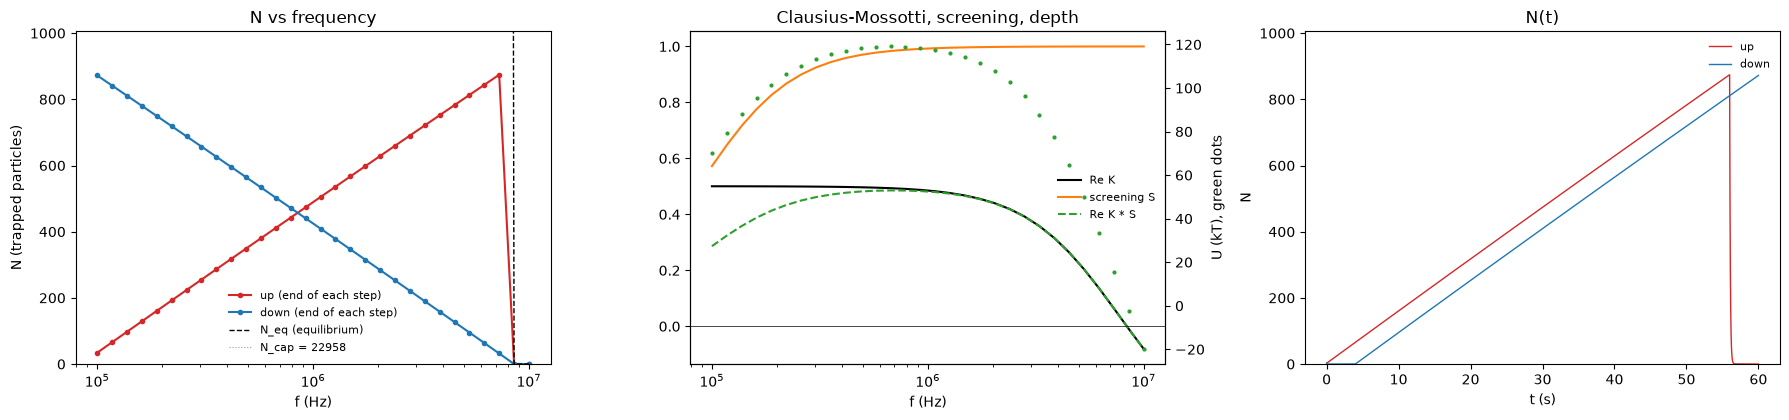

In [17]:
def physics(f, p):
    "Re K, screening S, depth U (kT), and the constants of the trap at frequencies f."
    sm = p["sigma_m"] * 1e-4                                              # S/m
    w_ = 2 * np.pi * f
    em = EPS_M - 1j * sm / w_
    if p["model"] == "au_sio2":
        a, b = p["a_core"] * 1e-9, (p["a_core"] + p["t_shell"]) * 1e-9
        ec, es = EPS0 - 1j * SIGMA_AU / w_, EPS_SIO2 + 0j
        G = (ec - es) / (ec + 2 * es)
        ep = es * ((b / a)**3 + 2 * G) / ((b / a)**3 - G) - 1j * 2 * p["K_s"] * 1e-9 / b / w_
    else:
        b = p["radius"] * 1e-9
        ep = p["eps_p"] * EPS0 - 1j * p["sigma_p"] * 1e-4 / w_
    ReK = ((ep - em) / (ep + 2 * em)).real
    if p["debye_nm"] is None:
        lam = 0.304e-9 / np.sqrt(sm / KCL_MOLAR_COND * 1e-3)             # Debye length (m): 0.304 nm / sqrt(c [M])
    else:
        lam = p["debye_nm"] * 1e-9
    Omega = w_ * p["Lambda"] * EPS_M / lam * ELL / sm
    S = Omega**2 / (1 + Omega**2)
    U0 = np.pi * EPS_M * b**3 * (p["V0"] / (p["gap"] * 1e-6))**2 / KT
    U = U0 * ReK * S
    D = KT / (6 * np.pi * ETA * b) * 1e12                                 # um^2/s
    c = p["c_inf"] * 1e-12                                                # 1/um^3
    N_cap = p["phi_max"] * p["V_trap"] / (4 / 3 * np.pi * (b * 1e6)**3)
    N_res = c * p["V_trap"]
    J_D = 4 * D * c * p["a_trap"]                                         # particles/s
    with np.errstate(over="ignore"):
        N_eq = N_cap / (1 + N_cap / N_res * np.exp(-U))
    tau_l = p["l_trap"]**2 / D / (1 + np.maximum(-U, 0))                  # s, time to cross the trap: diffusion + nDEP drift
    log_x = np.log(J_D * tau_l / N_res) - U                               # log(k_eq tau_l)
    g = 0.5 * (1 - np.tanh(log_x / 2))                                    # 1 / (1 + k_eq tau_l), overflow-safe
    gk = 0.5 * (1 + np.tanh(log_x / 2)) / tau_l                           # g k_eq = escape rate per particle
    return dict(f=f, ReK=ReK, S=S, Omega=Omega, U=U, U0=U0, D=D, N_cap=N_cap, N_res=N_res, J_D=J_D, N_eq=N_eq,
                tau_l=tau_l, g=g, k_out=gk,
                lam=lam, f_c=sm / (2 * np.pi * EPS_M))


def sweep(ph, direction, t_step, n_out=40):
    "Staircase over the frequencies; exact solution of dN/dt = A - B N on each step. Starts from N = N_res (no trap)."
    order = np.argsort(ph["f"])[::-1] if direction == "down" else np.argsort(ph["f"])
    J, Nc, Nr = ph["J_D"], ph["N_cap"], ph["N_res"]
    s = np.linspace(0, t_step, n_out + 1)[1:]
    N, t0 = Nr, 0.0
    ts, Ns, ends = [0.0], [N], []
    for i in order:
        A = ph["g"][i] * J                                    # capture (empty trap), particles/s
        B = A / Nc + ph["k_out"][i]                           # dN/dt = A - B N
        N_inf = A / B
        tr = N_inf + (N - N_inf) * np.exp(-B * s)
        ts.extend(t0 + s); Ns.extend(tr)
        N, t0 = tr[-1], t0 + t_step
        ends.append(N)
    o = np.argsort(ph["f"][order])
    return dict(t=np.array(ts), N=np.array(Ns), f=ph["f"][order][o], end=np.array(ends)[o])


def run(**kw):
    p = dict(P, **kw)
    f = np.logspace(np.log10(p["f_min"]), np.log10(p["f_max"]), int(p["n_f"]))
    ph = physics(f, p)
    return p, ph, {d: sweep(ph, d, p["t_step"]) for d in ("up", "down")}


def show(p, ph, sw):
    fx = ph["f"][np.where(np.diff(np.sign(ph["ReK"])) != 0)[0]]
    print(f"D = {ph['D']:.2f} um^2/s | J_D = 4Dca = {ph['J_D']:.2f} /s | N_cap = {ph['N_cap']:.0f} | N_res = c V_t = {ph['N_res']:.3g} | "
          f"fill time N_cap/J_D = {ph['N_cap'] / ph['J_D']:.0f} s | "
          f"l^2/D = {p['l_trap']**2 / ph['D']:.3g} s; with nDEP push, min tau_l = {ph['tau_l'].min():.3g} s")
    print(f"U0 = {ph['U0']:.0f} kT | lambda_D = {ph['lam'] * 1e9:.0f} nm | f_c = {ph['f_c'] / 1e3:.0f} kHz | "
          f"Omega = 1 at {ph['f'][0] / ph['Omega'][0] / 1e3:.0f} kHz | CM crossover(s) in the window: "
          + (", ".join(f"{x / 1e6:.2f} MHz" for x in fx) or "none"))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
    for d, col in (("up", "C3"), ("down", "C0")):
        ax[0].plot(sw[d]["f"], sw[d]["end"], ".-", color=col, label=f"{d} (end of each step)")
        ax[2].plot(sw[d]["t"], sw[d]["N"], color=col, lw=1, label=d)
    ax[0].plot(ph["f"], ph["N_eq"], "k--", lw=1, label="N_eq (equilibrium)")
    ax[0].axhline(ph["N_cap"], color="0.6", lw=0.8, ls=":", label=f"N_cap = {ph['N_cap']:.0f}")
    top = 1.15 * max(sw["up"]["N"].max(), sw["down"]["N"].max())      # N_eq and N_cap may lie above the view
    ax[0].set(xscale="log", ylim=(0, top),
              xlabel="f (Hz)", ylabel="N (trapped particles)", title="N vs frequency")
    ax[1].plot(ph["f"], ph["ReK"], "k-", label="Re K")
    ax[1].plot(ph["f"], ph["S"], "C1-", label="screening S")
    ax[1].plot(ph["f"], ph["ReK"] * ph["S"], "C2--", label="Re K * S")
    ax[1].axhline(0, color="k", lw=0.5)
    a1 = ax[1].twinx()
    a1.plot(ph["f"], ph["U"], "C2.", ms=4)
    a1.set(ylabel="U (kT), green dots")
    ax[1].set(xscale="log", xlabel="f (Hz)", title="Clausius-Mossotti, screening, depth")
    ax[2].set(ylim=(0, top), xlabel="t (s)", ylabel="N", title="N(t)")
    for a in ax:
        a.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


show(*run())

## Sliders
The curves update when a slider is released. Units as in the parameter cell.

In [18]:
log = lambda v, lo, hi, step=0.02: w.FloatLogSlider(value=v, base=10, min=lo, max=hi, step=step, continuous_update=False)
lin = lambda v, lo, hi, step: w.FloatSlider(value=v, min=lo, max=hi, step=step, continuous_update=False)
w.interact(lambda **kw: show(*run(**kw)),
           sigma_m=log(P["sigma_m"], 0, 3),        # 1 - 1000 uS/cm
           Lambda=log(P["Lambda"], -4, 0),
           K_s=log(P["K_s"], -2, 1.5),             # 0.01 - 30 nS
           a_core=lin(P["a_core"], 5, 100, 2.5),   # nm
           t_shell=lin(P["t_shell"], 2, 100, 2),   # nm
           debye_nm=log(P["debye_nm"], 0, 2),      # 1 - 100 nm
           V0=log(P["V0"], -1, 1),                 # 0.1 - 10 V
           gap=log(P["gap"], -1, 1),               # 0.1 - 10 um
           a_trap=log(P["a_trap"], -1, 2),         # 0.1 - 100 um
           l_trap=log(P["l_trap"], -1, 1.5),       # 0.1 - 30 um
           V_trap=log(P["V_trap"], -1, 3),         # 0.1 - 1000 um^3
           phi_max=lin(P["phi_max"], 0.05, 0.74, 0.01),
           c_inf=log(P["c_inf"], 8, 13),           # 1/mL
           t_step=log(P["t_step"], -1, 2.5),       # 0.1 - 300 s
           model=w.fixed(P["model"]), radius=w.fixed(P["radius"]), eps_p=w.fixed(P["eps_p"]), sigma_p=w.fixed(P["sigma_p"]),
           f_min=w.fixed(P["f_min"]), f_max=w.fixed(P["f_max"]), n_f=w.fixed(P["n_f"]));

interactive(children=(FloatLogSlider(value=118.0, continuous_update=False, description='sigma_m', max=3.0, ste…

## Compare cases
Each case overrides some keys of `P`. Default: Au@SiO2 in the three CTAC solutions of Fig. 3f (measured sigma_m, Debye length, Stern-fitted K_s). Left: up sweep, right: down sweep (N at the end of each step).

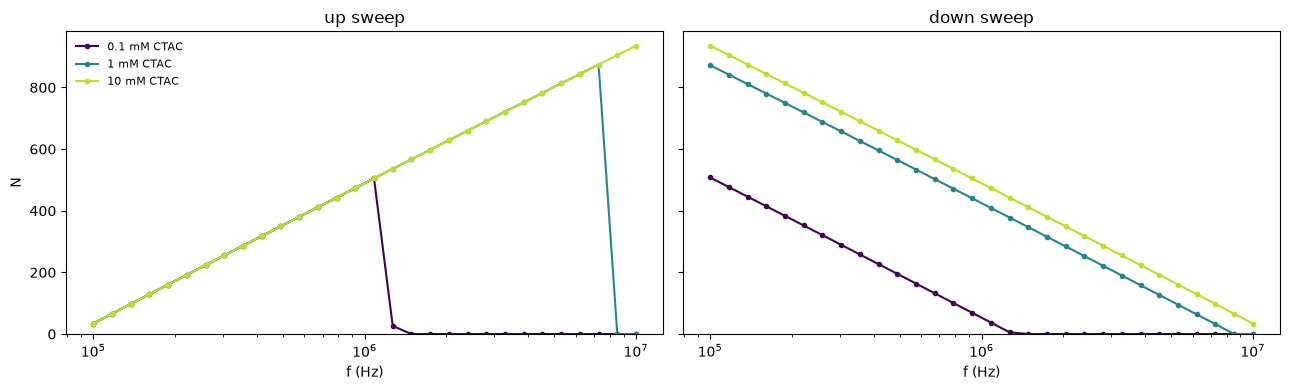

In [19]:
CASES = {
    "0.1 mM CTAC": dict(sigma_m=45.0, debye_nm=30.4, K_s=0.22),
    "1 mM CTAC": dict(),
    "10 mM CTAC": dict(sigma_m=427.0, debye_nm=4.6, K_s=3.15),
}
# one parameter instead: CASES = {f"l_trap = {v}": dict(l_trap=v) for v in (0.1, 1, 3, 10)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for (name, kw), col in zip(CASES.items(), plt.cm.viridis(np.linspace(0, 0.9, len(CASES)))):
    p, ph, sw = run(**kw)
    for a, d in zip(ax, ("up", "down")):
        a.plot(sw[d]["f"], sw[d]["end"], ".-", color=col, label=name)
for a, d in zip(ax, ("up", "down")):
    a.set(xscale="log", ylim=(0, None), xlabel="f (Hz)", title=f"{d} sweep")
ax[0].set_ylabel("N"); ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()